# 03 · Patient-similarity graph

The whole approach rests on one assumption: **clinically similar patients have
correlated outcomes, in a way that a patient's own feature row does not already
capture.** If that fails, message passing adds nothing, a plain gradient-boosted
tree wins, and an adaptive-depth GNN is elaborate machinery around no signal.

That exact failure was recorded on synthetic data in HANDOVER §6.2 — layer 1
saturated, the exit policy collapsed, and XGBoost beat every GNN. This notebook
tests the assumption on real data *before* any model is trained.

Three things get established:

1. the graph is well-formed (connected, sane degree distribution);
2. it is **homophilous** with respect to mortality, beyond chance;
3. neighbourhood information adds signal **at more than one hop** — which is
   what makes variable depth, and therefore early exit, meaningful at all.

In [1]:
exec(open("/kaggle/working/clinical-eegnn/notebooks/src/_bootstrap.py").read())
from src import mimic_iv, graph_build as gb
from src.data_prep import make_splits, impute_and_scale
from sklearn.metrics import roc_auc_score
import torch, matplotlib.pyplot as plt

cfg = mimic_cfg()
X_raw, y, names, meta = mimic_iv.build_cohort(cfg, verbose=False)
train, val, test = make_splits(y, cfg["seed"])
X = impute_and_scale(X_raw, train)
n = len(y)
print(f"{n:,} patients, {X.shape[1]} features after imputation "
      f"(+{X.shape[1]-X_raw.shape[1]} missingness indicators)")
print("device:", "cuda" if torch.cuda.is_available() else "cpu")

17,663 patients, 542 features after imputation (+211 missingness indicators)
device: cuda


## Scale note

An `[n, n]` similarity matrix at n = 46,651 is 8.7 GB in float32 and will not
coexist with a training run on this kernel. `build_knn_graph` therefore scores
in row blocks, keeping peak memory at `O(block x n)`, and uses the GPU when one
is available. The result is identical to the dense computation — same edges,
same weights — it just never materialises the whole matrix.

In [2]:
t0 = time.time()
ei, ew = gb.build_knn_graph(X, cfg["graph"]["k"], cfg["graph"]["similarity"])
print(f"k={cfg['graph']['k']}  {ei.shape[1]:,} directed edges  [{time.time()-t0:.1f}s]")

deg = np.bincount(ei[0], minlength=n)
print(f"degree: mean {deg.mean():.1f}  median {np.median(deg):.0f}  "
      f"min {deg.min()}  max {deg.max()}")
print(f"isolated nodes: {(deg == 0).sum()}")

k=15  426,496 directed edges  [0.7s]
degree: mean 24.1  median 20  min 15  max 176
isolated nodes: 0


Degrees exceed `k` because the graph is symmetrised: an edge is kept if *either*
endpoint chose the other. That is deliberate — a one-directional kNN graph makes
message passing asymmetric in a way that has no clinical meaning.

connected components: 3  (largest holds 99.7% of patients)


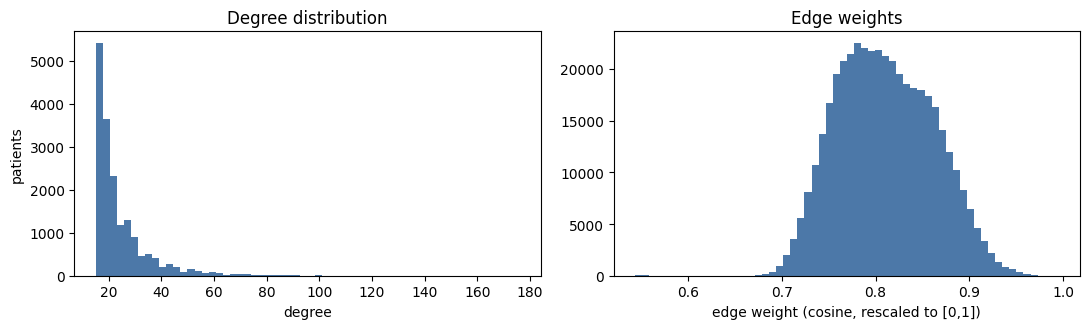

In [3]:
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components

A = sp.coo_matrix((ew, (ei[0], ei[1])), shape=(n, n)).tocsr()
ncomp, labels_cc = connected_components(A, directed=False)
sizes = np.bincount(labels_cc)
print(f"connected components: {ncomp}  (largest holds {sizes.max()/n:.1%} of patients)")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(deg, bins=60, color="#4C78A8")
ax[0].set_xlabel("degree"); ax[0].set_ylabel("patients"); ax[0].set_title("Degree distribution")
ax[1].hist(ew, bins=60, color="#4C78A8")
ax[1].set_xlabel("edge weight (cosine, rescaled to [0,1])"); ax[1].set_title("Edge weights")
plt.tight_layout(); plt.show()

## Homophily

Edge homophily is the share of edges joining two patients with the same
outcome. On its own that number is misleading under class imbalance: with 89%
survivors, a *random* graph already joins same-label pairs most of the time.

The meaningful quantity is homophily **against the chance baseline** for this
label distribution, so both are reported.

In [4]:
src, dst = ei[0], ei[1]
same = (y[src] == y[dst])
p = y.mean()
chance = p**2 + (1-p)**2

print(f"edge homophily        {same.mean():.4f}")
print(f"chance baseline       {chance:.4f}")
print(f"excess over chance    {same.mean()-chance:+.4f}")

# The share that actually matters clinically: given a patient who died, how
# often did they land next to another patient who died?
pos_edges = y[src] == 1
print(f"\nP(neighbour died | patient died)      {y[dst][pos_edges].mean():.4f}")
print(f"P(neighbour died | patient survived)  {y[dst][~pos_edges].mean():.4f}")
print(f"population rate                       {p:.4f}")

edge homophily        0.8624
chance baseline       0.8076
excess over chance    +0.0548

P(neighbour died | patient died)      0.3310
P(neighbour died | patient survived)  0.0767
population rate                       0.1078


## The decisive test: does the neighbourhood predict the outcome?

Homophily is a summary statistic. The operational question is whether
aggregating neighbours yields a usable predictor.

**Leakage control.** For any node, only *training* labels may be read. Val and
test labels are never aggregated, even though this is transductive learning and
those nodes are present in the graph.

In [5]:
y_train_only = np.where(train, y, 0.0).astype(np.float64)
is_train = train.astype(np.float64)

Abin = sp.coo_matrix((np.ones(len(src)), (src, dst)), shape=(n, n)).tocsr()

def neighbour_rate(k_hops):
    """Mean training-label among nodes within k hops (training nodes only)."""
    num, den = y_train_only.copy(), is_train.copy()
    for _ in range(k_hops):
        num, den = Abin @ num, Abin @ den
    return np.divide(num, den, out=np.full(n, np.nan), where=den > 0)

rows = []
for hops in (1, 2, 3, 4, 6, 8):
    r = neighbour_rate(hops)
    ok = np.isfinite(r) & val
    rows.append({"hops": hops,
                 "val_auroc": roc_auc_score(y[ok], r[ok]),
                 "coverage": ok.sum() / val.sum()})
hop = pd.DataFrame(rows)
print(hop.to_string(index=False))

 hops  val_auroc  coverage
    1   0.810932       1.0
    2   0.835918       1.0
    3   0.829722       1.0
    4   0.821068       1.0
    6   0.810589       1.0
    8   0.803696       1.0


Read this table carefully — it is the core evidence for the whole design.

- **1-hop AUROC well above 0.5** means the graph carries outcome signal that is
  not simply a restatement of each patient's own features.
- **AUROC still improving at 2-3 hops** means information has to *travel*, so a
  fixed shallow model leaves signal unused and depth is genuinely useful.
- **AUROC peaking then falling** locates over-smoothing: beyond that depth,
  neighbourhoods blur into the population average. That peak is roughly where
  `max_layers` should sit, and it is what an adaptive-exit policy should
  discover per patient.

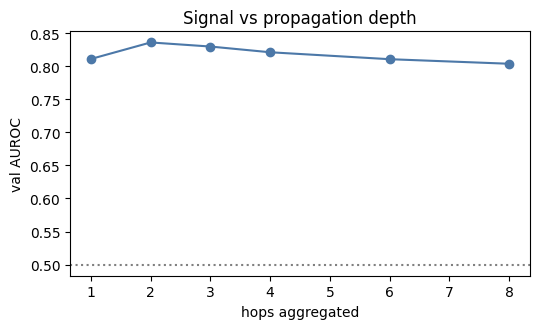

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
ax.plot(hop["hops"], hop["val_auroc"], "o-", color="#4C78A8")
ax.axhline(0.5, ls=":", c="grey"); ax.set_xlabel("hops aggregated")
ax.set_ylabel("val AUROC"); ax.set_title("Signal vs propagation depth")
plt.tight_layout(); plt.show()

## Choosing k and the similarity metric

k trades neighbourhood purity against coverage. Too small and the graph
fragments; too large and every patient is averaged toward the population mean.

In [7]:
rows = []
for k in (5, 10, 15, 25, 40):
    for sim in ("cosine", "euclidean_rbf"):
        e, w = gb.build_knn_graph(X, k, sim)
        s = (y[e[0]] == y[e[1]]).mean()
        Ab = sp.coo_matrix((np.ones(e.shape[1]), (e[0], e[1])), shape=(n, n)).tocsr()
        num, den = Ab @ y_train_only, Ab @ is_train
        r = np.divide(num, den, out=np.full(n, np.nan), where=den > 0)
        ok = np.isfinite(r) & val
        rows.append({"k": k, "similarity": sim, "edges": e.shape[1],
                     "homophily": s, "excess": s - chance,
                     "1hop_val_auroc": roc_auc_score(y[ok], r[ok])})
sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))

 k    similarity   edges  homophily   excess  1hop_val_auroc
 5        cosine  146724   0.865025 0.057377        0.760619
 5 euclidean_rbf  158890   0.874567 0.066919        0.722857
10        cosine  287678   0.863924 0.056276        0.805914
10 euclidean_rbf  315794   0.874165 0.066517        0.763579
15        cosine  426496   0.862414 0.054766        0.810932
15 euclidean_rbf  472918   0.872595 0.064947        0.782010
25        cosine  701104   0.861758 0.054110        0.824471
25 euclidean_rbf  786792   0.871394 0.063746        0.806553
40        cosine 1105306   0.861649 0.054001        0.840636
40 euclidean_rbf 1257002   0.870533 0.062885        0.812378


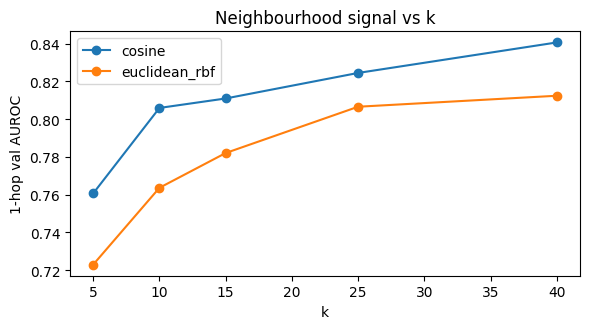

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for sim, g in sweep.groupby("similarity"):
    ax.plot(g["k"], g["1hop_val_auroc"], "o-", label=sim)
ax.set_xlabel("k"); ax.set_ylabel("1-hop val AUROC"); ax.legend()
ax.set_title("Neighbourhood signal vs k")
plt.tight_layout(); plt.show()

## Multi-view graph

Rather than one similarity over all features, build one kNN graph per feature
block and fuse them. A pair of patients similar under several views gets a
stronger edge — the GCRS-style hybrid.

The view membership comes from `meta["views"]`, the real block boundaries
reported by the ETL. Earlier this used a placeholder that split feature columns
into equal contiguous chunks, which does not correspond to any clinical
grouping; on real data that fallback is no longer used.

In [9]:
per_view = {}
for name, cols in meta["views"].items():
    cols = [c for c in cols if c < X.shape[1]]
    e, w = gb.build_knn_graph(X[:, cols], cfg["graph"]["k"], cfg["graph"]["similarity"])
    s = (y[e[0]] == y[e[1]]).mean()
    Ab = sp.coo_matrix((np.ones(e.shape[1]), (e[0], e[1])), shape=(n, n)).tocsr()
    num, den = Ab @ y_train_only, Ab @ is_train
    r = np.divide(num, den, out=np.full(n, np.nan), where=den > 0)
    ok = np.isfinite(r) & val
    per_view[name] = {"cols": len(cols), "edges": e.shape[1], "homophily": s,
                      "excess": s - chance, "1hop_val_auroc": roc_auc_score(y[ok], r[ok])}
print(pd.DataFrame(per_view).T.to_string())

               cols     edges  homophily    excess  1hop_val_auroc
demographics   33.0  326604.0   0.824007  0.016359        0.664187
comorbidity    19.0  486028.0   0.835874  0.028226        0.520343
labs          168.0  422240.0   0.844704  0.037056        0.743306
vitals         84.0  415346.0   0.849730  0.042082        0.786030
treatment      27.0  338418.0   0.831203  0.023555        0.720365


In [10]:
t0 = time.time()
ei_mv, ew_mv = gb.build_multiview_graph(
    gb._views_from(X, cfg, meta), cfg["graph"]["k"], cfg["graph"]["similarity"])
print(f"fused graph: {ei_mv.shape[1]:,} edges  [{time.time()-t0:.1f}s]")

s = (y[ei_mv[0]] == y[ei_mv[1]]).mean()
Ab = sp.coo_matrix((np.ones(ei_mv.shape[1]), (ei_mv[0], ei_mv[1])), shape=(n, n)).tocsr()
num, den = Ab @ y_train_only, Ab @ is_train
r = np.divide(num, den, out=np.full(n, np.nan), where=den > 0)
ok = np.isfinite(r) & val
print(f"homophily {s:.4f} (excess {s-chance:+.4f})   "
      f"1-hop val AUROC {roc_auc_score(y[ok], r[ok]):.4f}")

fused graph: 1,969,314 edges  [1.1s]
homophily 0.8376 (excess +0.0299)   1-hop val AUROC 0.8459


Whether fusion beats the single all-feature graph is an empirical question, and
the numbers above answer it for this cohort. Fusion helps when views disagree
about who is similar; it does nothing when one block dominates the similarity
anyway.

## Build and cache the graph the models will use

In [11]:
from src.graph_build import build_graph, describe

data = build_graph(X, y, (train, val, test), cfg, meta=meta, cache_dir=CACHE)
print(describe(data))
# Severity proxies attached for the safety analysis in notebooks 05-06. Neither
# is a model input; the model reads `data.x` alone.
for attr in ("severity", "criticalness", "true_risk"):
    print(f"  {attr:14s} attached: {hasattr(data, attr)}")

json.dump({
    "n_nodes": int(n), "n_edges": int(ei.shape[1]),
    "mean_degree": float(deg.mean()), "components": int(ncomp),
    "homophily": float(same.mean()), "chance": float(chance),
    "hop_auroc": hop.to_dict("records"),
    "k_sweep": sweep.to_dict("records"),
    "per_view": per_view,
}, open(f"{CACHE}/graph_summary.json", "w"), indent=2, default=float)
print("\nwrote graph_summary.json")

nodes=17663 edges=426496 avg_degree=24.15 features=542 prevalence={'train': 0.10776635259389877, 'val': 0.10784035921096802, 'test': 0.10784035921096802}
  severity       attached: True
  criticalness   attached: True
  true_risk      attached: False

wrote graph_summary.json


## What this determines for the model

- **`max_layers`** should cover the depth at which hop-AUROC peaks; there is no
  point budgeting propagation past the point where neighbourhoods stop being
  informative.
- **If the hop curve is flat after 1 hop**, depth cannot be the thing that
  distinguishes patients, and the exit policy will collapse to all-shallow —
  the synthetic failure of HANDOVER §6.2, reproduced on real data. In that case
  the honest conclusion is that early exit saves compute without any accuracy
  trade-off worth studying, which is a much weaker claim than the one the
  project set out to make.
- **The 1-hop AUROC is the floor for the GNN.** A trained model that cannot beat
  simple neighbour-averaging is not using the graph.

**Next:** `04_baselines` — GCN, GAT, XGBoost and a fixed-threshold early-exit
control on this cohort, which is what the multi-exit model must beat.